# Step 3 — Ethereum: validazione esatta EIP-1559

Ricostruiamo la base fee del figlio dai dati del closed parent usando aritmetica intera.
Questo è un controllo strutturale sull'intero dataset, senza stima o tolleranza numerica.
Riferimento primario: [specifica EIP-1559](https://eips.ethereum.org/EIPS/eip-1559#specification).

## Risultati dell’esecuzione

1.654.535 coppie consecutive verificate: zero discrepanze e residuo massimo zero wei/gas.
Non viene creato findings.md perché questo step non ha rilevato anomalie della ricorrenza.

## Copertura e applicabilità

Il dataset mainnet inizia al blocco 23.935.694, successivo a London (12.965.000).
Usiamo il target del padre `gas_limit // 2` e denominatore 8; il controllo coppia per coppia verifica
empiricamente l'applicabilità di questa ricorrenza all'intero intervallo, anche quando cambia il gas limit.
Ogni discrepanza viene esportata integralmente: un controllo riuscito non verifica altri campi di consenso.

## Ambiente e input

Usiamo il kernel Python 3.11 del progetto e gli artefatti verificati dello step 1.
Il notebook è autonomo rispetto alle variabili in memoria degli altri step; tutte le fee sono in wei/gas.

## Caricamento dei dati preparati nello step 1

Rileggiamo Parquet e riepilogo del preprocessing in un kernel nuovo.
Controlliamo chain, UUID e numero di righe prima di ricostruire le transizioni.

In [1]:
import json
import operator
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

CHAIN = "ethereum"
CHAIN_LABEL = "Ethereum"
EXPECTED_CHAIN_ID = 1
DATASET_ID = "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
TARGET_PERCENTAGE = 50
CHANGE_DENOMINATOR = 8
MAX_PLOT_POINTS = 4000
EXPORT_DIAGNOSTICS = True

plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "figure.dpi": 110,
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)
COLOR = "#2459A6"
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 20)

ancestors = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (
        p
        for p in ancestors
        if (p / "pyproject.toml").is_file() and (p / "docs/CONTEXT.md").is_file()
    ),
    Path.cwd(),
)

input_directory = project_root / "outputs/notebook_diagnostics" / CHAIN / "step1"
input_parquet = input_directory / f"{CHAIN}_blocks_diagnostics.parquet"
input_summary = input_directory / "preprocessing_summary.json"
if not input_parquet.is_file() or not input_summary.is_file():
    raise FileNotFoundError(
        "Eseguire prima step1/dataset_ethereum.ipynb con EXPORT_DIAGNOSTICS=True."
    )
df = pd.read_parquet(input_parquet)
preprocessing_summary = json.loads(input_summary.read_text())
assert preprocessing_summary["chain_id"] == EXPECTED_CHAIN_ID
assert preprocessing_summary["dataset_id"] == DATASET_ID
assert len(df) == preprocessing_summary["rows"]
RAW_COLUMNS = tuple(preprocessing_summary["raw_columns"])
output_directory = project_root / "outputs/notebook_diagnostics" / CHAIN / "step3"
output_directory.mkdir(parents=True, exist_ok=True)
print("Input preprocessing:", input_parquet)
print("Output step 3:", output_directory)

Input preprocessing: /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step1/ethereum_blocks_diagnostics.parquet
Output step 3: /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step3


### Assunzioni di protocollo — Ethereum mainnet

Dataset interamente successivo a London: target `parent_gas_limit // 2`,
denominatore `8`. La base fee successiva è determinata esattamente dai
tre dati del blocco precedente. Una differenza di un solo wei è una
discrepanza, senza tolleranze numeriche.

Riferimento: [EIP-1559, specifica](https://eips.ethereum.org/EIPS/eip-1559#specification).

## Allineamento padre–figlio

Prepariamo gli indici ordinati per verificare che ogni figlio segua immediatamente il padre.
Il primo blocco non ha un predecessore interno al campione e non viene confrontato.

In [2]:
block_numbers = df["block_number"].to_numpy()
block_difference = np.diff(block_numbers)

## Funzione per la base fee del blocco immediatamente successivo

La funzione viene definita prima del suo utilizzo. Gli argomenti posizionali
sono i dati **del blocco precedente**, senza conversioni intermedie in float.

In [3]:
def calculate_next_base_fee(base_fee, gas_used, gas_limit):
    """Base fee esatta del figlio Ethereum, in wei/gas (post-London)."""
    base_fee, gas_used, gas_limit = map(operator.index, (base_fee, gas_used, gas_limit))
    target = gas_limit // 2
    if base_fee <= 0 or target <= 0 or not 0 <= gas_used <= gas_limit:
        raise ValueError("Dati del blocco precedente non validi")
    if gas_used == target:
        return base_fee
    if gas_used > target:
        delta = max(base_fee * (gas_used - target) // target // 8, 1)
        return base_fee + delta
    delta = base_fee * (target - gas_used) // target // 8
    return base_fee - delta


# Vettori indipendenti per divisioni intere e minimo di un wei.
assert calculate_next_base_fee(1000, 50, 100) == 1000
assert calculate_next_base_fee(1000, 100, 100) == 1125
assert calculate_next_base_fee(1000, 0, 100) == 875
assert calculate_next_base_fee(1, 51, 100) == 2
assert calculate_next_base_fee(1, 49, 100) == 1
assert calculate_next_base_fee(1000, 50, 101) == 1000
assert calculate_next_base_fee(2**100, 100, 100) == 9 * 2**97
print("Funzione Ethereum: controlli di arrotondamento superati.")

Funzione Ethereum: controlli di arrotondamento superati.


## Ricostruzione della base fee attesa

Applichiamo la funzione intera a base fee, gas usato e gas limit di ogni padre.
Ogni previsione riguarda il figlio immediato, senza usare il gas del figlio.

In [4]:
base_fees = df["base_fee_per_gas"].to_numpy()
gas_used = df["gas_used"].to_numpy()
gas_limits = df["gas_limit"].to_numpy()
expected_next = np.fromiter(
    (
        calculate_next_base_fee(int(b), int(g), int(limit))
        for b, g, limit in zip(base_fees[:-1], gas_used[:-1], gas_limits[:-1], strict=True)
    ),
    dtype=np.int64,
    count=len(df) - 1,
)

## Confronto esatto con le fee osservate

Allineiamo la base fee ricostruita al blocco figlio e calcoliamo il residuo in wei/gas.
La tolleranza è zero; coppie non consecutive non possono certificare la ricorrenza.

In [5]:
consecutive = block_difference == 1
df["expected_base_fee"] = pd.Series(expected_next, index=df.index[1:], dtype="Int64")
df.loc[df.index[1:][~consecutive], "expected_base_fee"] = pd.NA
df["base_fee_residual"] = df["base_fee_per_gas"].astype("Int64") - df["expected_base_fee"]
residuals = df["base_fee_residual"].dropna()
reference_mismatches = int(residuals.ne(0).sum())
exact_matches = int(residuals.eq(0).sum())
max_abs_residual = int(residuals.abs().max()) if len(residuals) else None

protocol_valid = base_fees[1:] == expected_next
protocol_description = "Uguaglianza esatta con la ricorrenza Ethereum"
protocol_valid = pd.Series(protocol_valid, index=df.index[1:], dtype="boolean")
protocol_valid.loc[df.index[1:][~consecutive]] = pd.NA
df["base_fee_protocol_valid"] = protocol_valid
protocol_violations = int(protocol_valid.eq(False).sum())
checked_pairs = int(consecutive.sum())

print(protocol_description)
display(
    pd.Series(
        {
            "Coppie consecutive controllate": checked_pairs,
            "Coincidenze con il calcolo di riferimento": exact_matches,
            "Scostamenti dal calcolo di riferimento": reference_mismatches,
            "Massimo residuo assoluto del riferimento (wei/gas)": max_abs_residual,
            "Violazioni della regola di consenso sulla base fee": protocol_violations,
        },
        name="Conteggio / valore",
    ).to_frame()
)
display(
    df[
        [
            "block_number",
            "base_fee_per_gas",
            "expected_base_fee",
            "base_fee_residual",
            "base_fee_protocol_valid",
        ]
    ].head(6)
)
display(
    df.loc[
        df["base_fee_residual"].ne(0).fillna(False),
        ["block_number", "base_fee_per_gas", "expected_base_fee", "base_fee_residual"],
    ].head(10)
)

Uguaglianza esatta con la ricorrenza Ethereum


,Conteggio / valore
Coppie consecutive controllate,1654535
Coincidenze con il calcolo di riferimento,1654535
Scostamenti dal calcolo di riferimento,0
Massimo residuo assoluto del riferimento (wei/gas),0
Violazioni della regola di consenso sulla base fee,0


,block_number,base_fee_per_gas,expected_base_fee,base_fee_residual,base_fee_protocol_valid
0,23935694,31400124,<NA>,<NA>,<NA>
1,23935695,31853945,31853945,0,True
2,23935696,34755102,34755102,0,True
3,23935697,30711148,30711148,0,True
4,23935698,27809171,27809171,0,True
5,23935699,25588596,25588596,0,True


,block_number,base_fee_per_gas,expected_base_fee,base_fee_residual


## Investigazione di tutte le discrepanze

Esportiamo l’elenco completo dei blocchi con residuo non nullo, senza fermarci ai primi casi.
Se l’elenco è vuoto non ci sono discrepanze da investigare per questa ricorrenza.

In [6]:
mismatches = df.loc[
    df["base_fee_residual"].ne(0).fillna(False),
    ["block_number", "base_fee_per_gas", "expected_base_fee", "base_fee_residual"],
]
mismatches.to_csv(output_directory / "all_recurrence_mismatches.csv", index=False)
assert checked_pairs == len(df) - 1
print("Discrepanze da investigare:", len(mismatches))

Discrepanze da investigare: 0


## Base fee e residui nel tempo

Mostriamo l’andamento delle fee e la differenza rispetto al protocollo.
Solo il grafico è decimato; il conteggio delle discrepanze usa tutte le coppie.

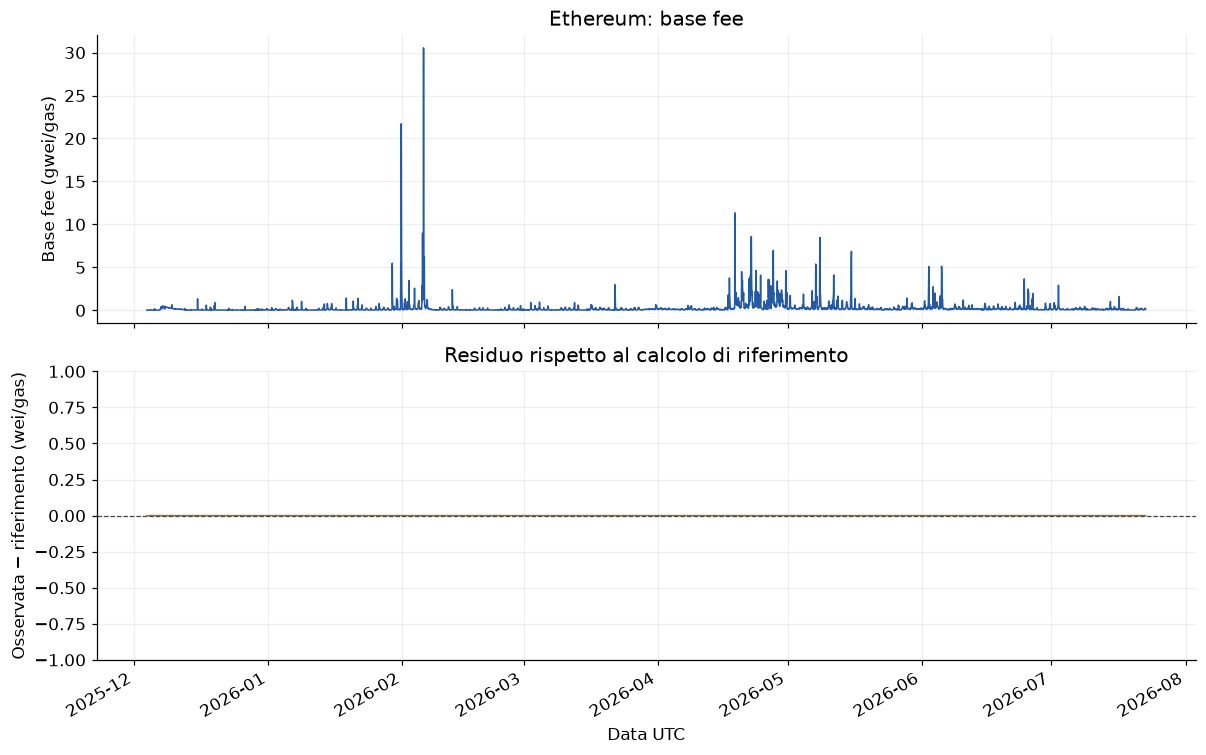

Grafico: una riga ogni 414; conteggi e controlli su tutte le righe.


In [7]:
plot_stride = max(1, int(np.ceil(len(df) / MAX_PLOT_POINTS)))
plot_rows = np.unique(np.r_[np.arange(0, len(df), plot_stride), len(df) - 1])
shown = df.iloc[plot_rows]
plot_dates = pd.to_datetime(shown["timestamp"], unit="s", utc=True)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(plot_dates, shown["base_fee_gwei"], color=COLOR, linewidth=1)
axes[0].set(title=f"{CHAIN_LABEL}: base fee", ylabel="Base fee (gwei/gas)")
axes[1].plot(
    plot_dates,
    shown["base_fee_residual"].to_numpy(dtype=float, na_value=np.nan),
    color="#B06C19",
    linewidth=1,
)
axes[1].axhline(0, color="#444444", linestyle="--", linewidth=0.8)
axes[1].set(
    title="Residuo rispetto al calcolo di riferimento",
    ylabel="Osservata − riferimento (wei/gas)",
    xlabel="Data UTC",
)
if max_abs_residual == 0:
    axes[1].set_ylim(-1, 1)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)
print(f"Grafico: una riga ogni {plot_stride}; conteggi e controlli su tutte le righe.")

## Report della verifica EIP-1559

Esportiamo conteggi, residui massimi, identità della fonte e tutte le discrepanze.
Zero discrepanze attesta questa ricorrenza e non costituisce una verifica completa del consenso.

In [8]:
report = pd.Series(
    {
        "Coppie consecutive verificate": checked_pairs,
        "Scostamenti dal riferimento": reference_mismatches,
        "Violazioni del consenso sulla base fee": protocol_violations,
    },
    name="Conteggio",
)
display(report.to_frame())
verification_summary = {
    key: preprocessing_summary[key]
    for key in (
        "chain",
        "chain_id",
        "dataset_id",
        "source_doi",
        "dataset_sha256",
        "rows",
        "first_block",
        "last_block",
        "complete_range",
        "raw_missing_values",
    )
}
verification_summary.update(
    {
        "consecutive_pairs": checked_pairs,
        "reference_exact_matches": exact_matches,
        "reference_mismatches": reference_mismatches,
        "reference_max_absolute_residual_wei": max_abs_residual,
        "protocol_violations": protocol_violations,
        "protocol_check": protocol_description,
        "reference_parameters": {
            "target_percentage": TARGET_PERCENTAGE,
            "denominator": CHANGE_DENOMINATOR,
        },
        "derived_missing_values": int(df.drop(columns=list(RAW_COLUMNS)).isna().sum().sum()),
    }
)
report.to_csv(output_directory / "base_fee_report.csv")
(output_directory / "base_fee_verification.json").write_text(
    json.dumps(verification_summary, indent=2) + "\n"
)
if EXPORT_DIAGNOSTICS:
    df.to_parquet(output_directory / f"{CHAIN}_blocks_diagnostics.parquet", index=False)
print("Coppie controllate:", f"{checked_pairs:,}")
print("Violazioni della regola di consenso:", protocol_violations)
print("Ricorrenza Ethereum esatta:", "PASS" if reference_mismatches == 0 else "FAIL")
print("Risultati step 3 salvati in:", output_directory)

,Conteggio
Coppie consecutive verificate,1654535
Scostamenti dal riferimento,0
Violazioni del consenso sulla base fee,0


Coppie controllate: 1,654,535
Violazioni della regola di consenso: 0
Ricorrenza Ethereum esatta: PASS
Risultati step 3 salvati in: /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step3
